In [ ]:
# Run sensitivity analysis

# 6A: Loss Event Frequency Sensitivity Analysis

import sys
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

cwd = Path.cwd().resolve()
project_root = cwd if (cwd / "config").exists() else cwd.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import src.sensitivity_analysis as sensitivity_module

importlib.reload(sensitivity_module)

run_frequency_sensitivity = (
    sensitivity_module.run_frequency_sensitivity
)

BASELINE_SUCCESS_PROBABILITY = (
    sensitivity_module.BASELINE_SUCCESS_PROBABILITY
)

# Run 100,000 years for each scenario
results, annual_losses_by_scenario = run_frequency_sensitivity(
    n_years=100_000,
    seed=20261025,
)

print("Sensitivity analysis completed.")
print(f"Scenarios: {len(results)}")
print("Simulated years per scenario: 100,000")

# Create readable display labels
formatted_results = results.copy()

formatted_results["Scenario"] = formatted_results.apply(
    lambda row: (
        f"{row['parameter_value']:g} campaigns/year"
        if row["parameter"] == "campaign_rate"
        else f"{row['parameter_value']:.2%} success probability"
    ),
    axis=1,
)

display_columns = {
    "Scenario": "Scenario",
    "expected_lef": "Expected LEF",
    "simulated_lef": "Simulated LEF",
    "probability_any_incident": "P(Any Incident)",
    "aal_usd": "AAL",
    "var_95_usd": "VaR 95%",
    "var_99_usd": "VaR 99%",
    "tvar_99_usd": "TVaR 99%",
    "p_loss_gt_2m": "P(Loss > $2M)",
    "p_loss_gt_5m": "P(Loss > $5M)",
}

formatted_results = formatted_results[
    list(display_columns)
].rename(columns=display_columns)

display(
    formatted_results.style.format({
        "Expected LEF": "{:.4f}",
        "Simulated LEF": "{:.4f}",
        "P(Any Incident)": "{:.2%}",
        "AAL": "${:,.0f}",
        "VaR 95%": "${:,.0f}",
        "VaR 99%": "${:,.0f}",
        "TVaR 99%": "${:,.0f}",
        "P(Loss > $2M)": "{:.2%}",
        "P(Loss > $5M)": "{:.2%}",
    })
)

Sensitivity analysis completed.
Scenarios: 10
Simulated years per scenario: 100,000


,Scenario,Expected LEF,Simulated LEF,P(Any Incident),AAL,VaR 95%,VaR 99%,TVaR 99%,P(Loss > $2M),P(Loss > $5M)
0,1 campaigns/year,0.0744,0.0741,7.14%,"$89,747","$617,594","$2,204,330","$3,416,772",1.19%,0.09%
1,2 campaigns/year,0.1488,0.1488,13.84%,"$183,109","$1,289,611","$3,116,969","$4,536,093",2.55%,0.25%
2,3 campaigns/year,0.2231,0.2216,19.88%,"$272,725","$1,730,117","$3,793,562","$5,285,004",3.99%,0.43%
3,4 campaigns/year,0.2975,0.2974,25.71%,"$363,766","$2,137,619","$4,174,799","$5,743,342",5.55%,0.57%
4,5 campaigns/year,0.3719,0.3718,31.19%,"$455,651","$2,441,598","$4,677,463","$6,234,017",7.02%,0.81%
5,3.00% success probability,0.0900,0.0907,8.66%,"$112,089","$810,493","$2,504,861","$3,825,734",1.52%,0.15%
6,5.00% success probability,0.1500,0.1513,14.06%,"$186,827","$1,303,275","$3,179,928","$4,685,079",2.59%,0.29%
7,7.44% success probability,0.2231,0.2216,19.88%,"$272,725","$1,730,117","$3,793,562","$5,285,004",3.99%,0.43%
8,10.00% success probability,0.3000,0.2999,25.88%,"$368,591","$2,134,691","$4,245,900","$5,791,874",5.58%,0.59%
9,15.00% success probability,0.4500,0.4518,36.30%,"$558,446","$2,788,643","$5,090,504","$6,687,326",9.03%,1.06%


In [7]:
#Campaign frequency sensitivity

campaign_results = (
    results[
        results["parameter"] == "campaign_rate"
    ]
    .sort_values("parameter_value")
    .copy()
)

display(
    campaign_results[
        [
            "parameter_value",
            "expected_lef",
            "probability_any_incident",
            "aal_usd",
            "var_99_usd",
            "tvar_99_usd",
            "p_loss_gt_2m",
            "p_loss_gt_5m",
        ]
    ].style.format({
        "parameter_value": "{:.0f}",
        "expected_lef": "{:.4f}",
        "probability_any_incident": "{:.2%}",
        "aal_usd": "${:,.0f}",
        "var_99_usd": "${:,.0f}",
        "tvar_99_usd": "${:,.0f}",
        "p_loss_gt_2m": "{:.2%}",
        "p_loss_gt_5m": "{:.2%}",
    })
)

,parameter_value,expected_lef,probability_any_incident,aal_usd,var_99_usd,tvar_99_usd,p_loss_gt_2m,p_loss_gt_5m
0,1,0.0744,7.14%,"$89,747","$2,204,330","$3,416,772",1.19%,0.09%
1,2,0.1488,13.84%,"$183,109","$3,116,969","$4,536,093",2.55%,0.25%
2,3,0.2231,19.88%,"$272,725","$3,793,562","$5,285,004",3.99%,0.43%
3,4,0.2975,25.71%,"$363,766","$4,174,799","$5,743,342",5.55%,0.57%
4,5,0.3719,31.19%,"$455,651","$4,677,463","$6,234,017",7.02%,0.81%


In [8]:
#Campaign success probability sensitivity

success_results = (
    results[
        results["parameter"] == "success_probability"
    ]
    .sort_values("parameter_value")
    .copy()
)

display(
    success_results[
        [
            "parameter_value",
            "expected_lef",
            "probability_any_incident",
            "aal_usd",
            "var_99_usd",
            "tvar_99_usd",
            "p_loss_gt_2m",
            "p_loss_gt_5m",
        ]
    ].style.format({
        "parameter_value": "{:.2%}",
        "expected_lef": "{:.4f}",
        "probability_any_incident": "{:.2%}",
        "aal_usd": "${:,.0f}",
        "var_99_usd": "${:,.0f}",
        "tvar_99_usd": "${:,.0f}",
        "p_loss_gt_2m": "{:.2%}",
        "p_loss_gt_5m": "{:.2%}",
    })
)

,parameter_value,expected_lef,probability_any_incident,aal_usd,var_99_usd,tvar_99_usd,p_loss_gt_2m,p_loss_gt_5m
5,3.00%,0.0900,8.66%,"$112,089","$2,504,861","$3,825,734",1.52%,0.15%
6,5.00%,0.1500,14.06%,"$186,827","$3,179,928","$4,685,079",2.59%,0.29%
7,7.44%,0.2231,19.88%,"$272,725","$3,793,562","$5,285,004",3.99%,0.43%
8,10.00%,0.3000,25.88%,"$368,591","$4,245,900","$5,791,874",5.58%,0.59%
9,15.00%,0.4500,36.30%,"$558,446","$5,090,504","$6,687,326",9.03%,1.06%


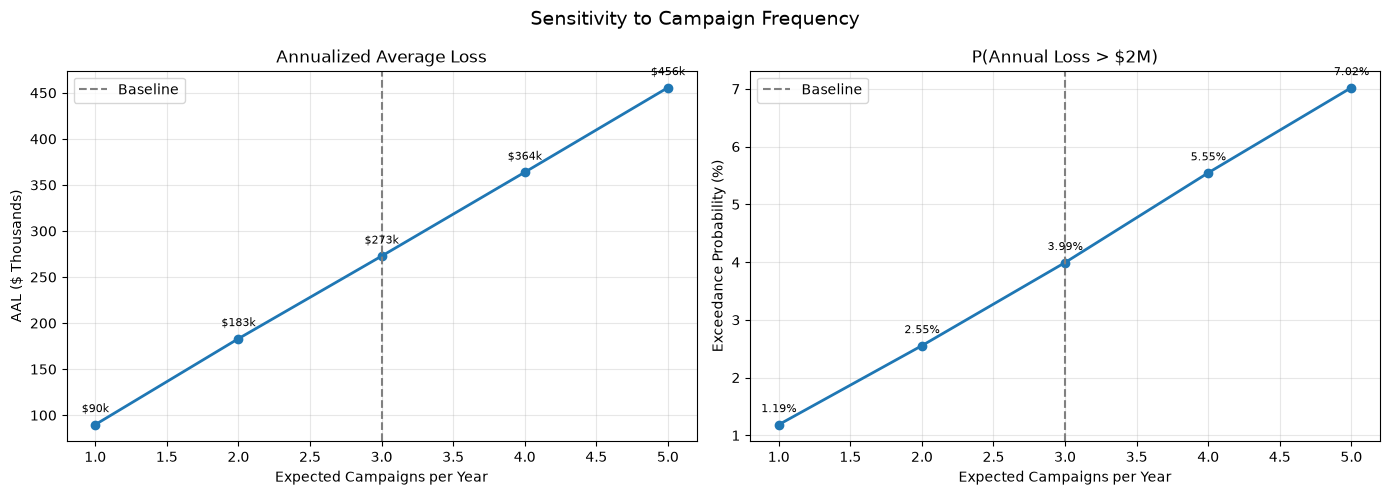

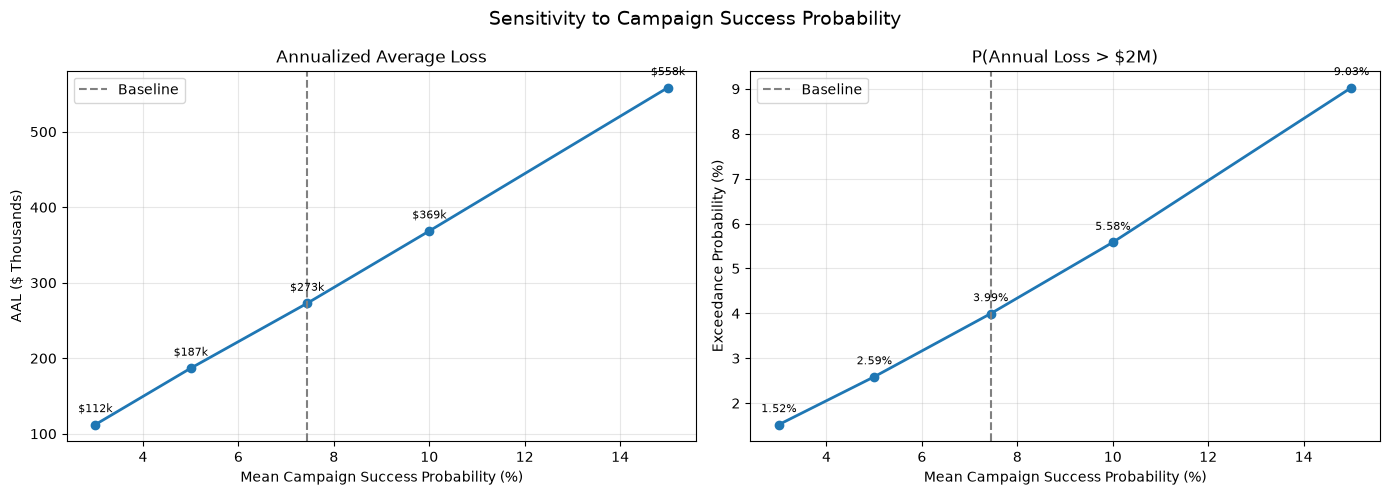

In [9]:
#Compare AAL and fixed-threshold exceedance probability

#AAL and exceedance sensitivity plots

LOSS_THRESHOLD = 2_000_000


def plot_sensitivity_comparison(
    results,
    annual_losses_by_scenario,
    parameter,
    threshold=LOSS_THRESHOLD,
):
    subset = (
        results[results["parameter"] == parameter]
        .sort_values("parameter_value")
        .copy()
    )

    subset["exceedance_probability"] = [
        np.mean(
            annual_losses_by_scenario[
                (parameter, float(value))
            ] > threshold
        )
        for value in subset["parameter_value"]
    ]

    is_probability = parameter == "success_probability"

    if is_probability:
        x = subset["parameter_value"].to_numpy() * 100
        xlabel = "Mean Campaign Success Probability (%)"
        baseline_x = BASELINE_SUCCESS_PROBABILITY * 100
    else:
        x = subset["parameter_value"].to_numpy()
        xlabel = "Expected Campaigns per Year"
        baseline_x = 3

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # AAL plot
    axes[0].plot(
        x,
        subset["aal_usd"] / 1000,
        marker="o",
        linewidth=2,
    )

    axes[0].axvline(
        baseline_x,
        linestyle="--",
        color="gray",
        label="Baseline",
    )

    axes[0].set_xlabel(xlabel)
    axes[0].set_ylabel("AAL ($ Thousands)")
    axes[0].set_title("Annualized Average Loss")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    for xi, yi in zip(x, subset["aal_usd"] / 1000):
        axes[0].annotate(
            f"${yi:,.0f}k",
            (xi, yi),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )

    # Exceedance probability plot
    probabilities = subset["exceedance_probability"] * 100

    axes[1].plot(
        x,
        probabilities,
        marker="o",
        linewidth=2,
    )

    axes[1].axvline(
        baseline_x,
        linestyle="--",
        color="gray",
        label="Baseline",
    )

    axes[1].set_xlabel(xlabel)
    axes[1].set_ylabel("Exceedance Probability (%)")
    axes[1].set_title(
        f"P(Annual Loss > ${threshold / 1e6:g}M)"
    )
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    for xi, yi in zip(x, probabilities):
        axes[1].annotate(
            f"{yi:.2f}%",
            (xi, yi),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )

    fig.suptitle(
        "Sensitivity to "
        + (
            "Campaign Success Probability"
            if is_probability
            else "Campaign Frequency"
        ),
        fontsize=14,
    )

    plt.tight_layout()
    plt.show()


plot_sensitivity_comparison(
    results,
    annual_losses_by_scenario,
    parameter="campaign_rate",
)

plot_sensitivity_comparison(
    results,
    annual_losses_by_scenario,
    parameter="success_probability",
)

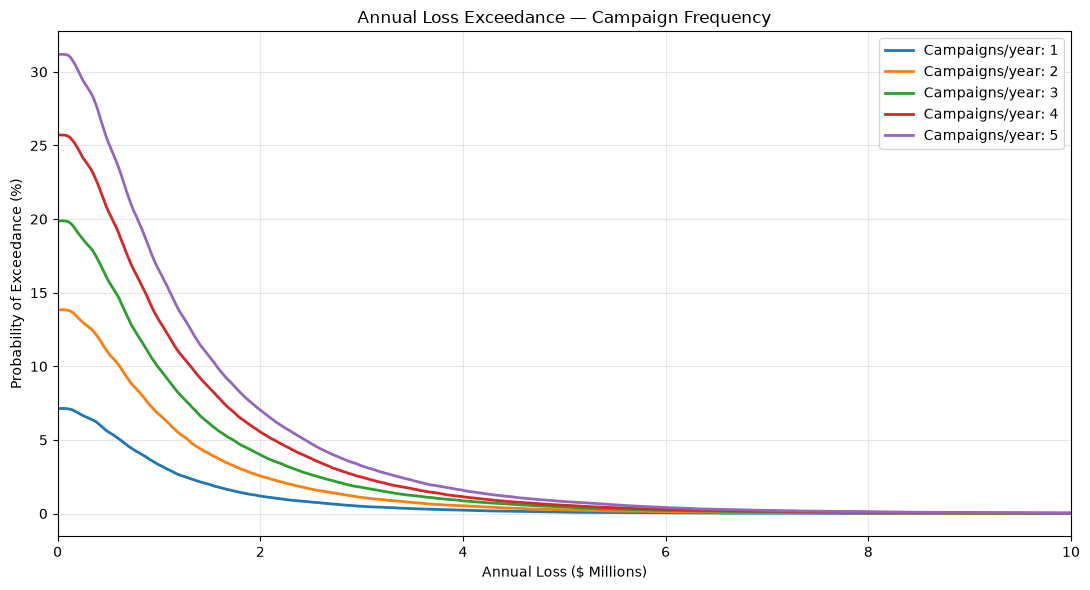

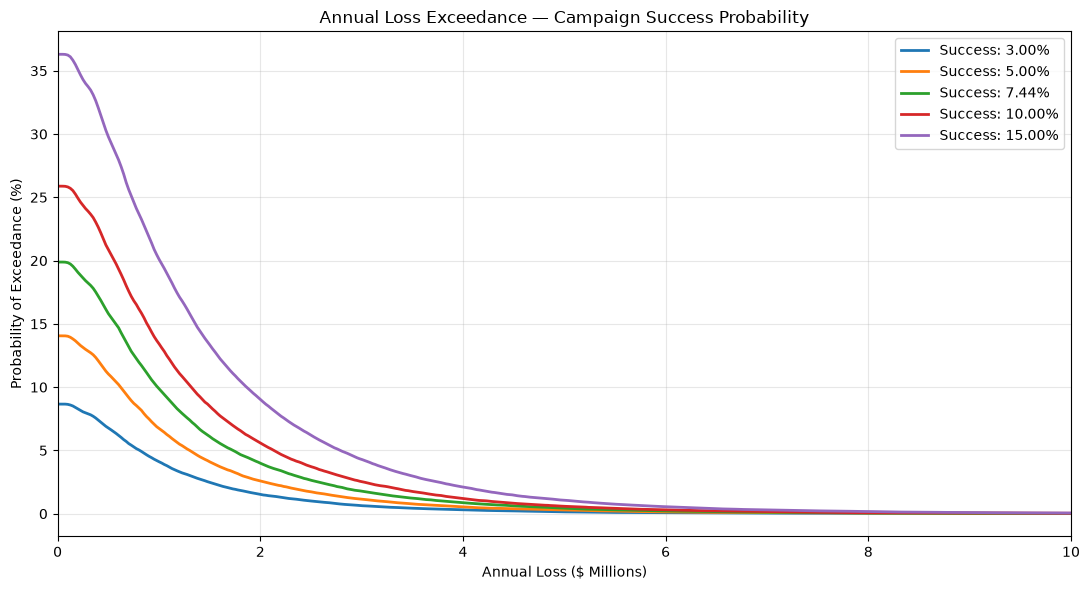

In [10]:
# Full annual loss exceedance curves


def plot_exceedance_curves(
    annual_losses_by_scenario,
    parameter,
    max_loss_millions=10,
):
    thresholds = np.linspace(
        0,
        max_loss_millions * 1_000_000,
        400,
    )

    scenarios = sorted(
        [
            (key, losses)
            for key, losses in annual_losses_by_scenario.items()
            if key[0] == parameter
        ],
        key=lambda item: item[0][1],
    )

    fig, ax = plt.subplots(figsize=(11, 6))

    for (name, value), losses in scenarios:
        sorted_losses = np.sort(losses)

        probabilities = 1 - (
            np.searchsorted(
                sorted_losses,
                thresholds,
                side="right",
            ) / len(sorted_losses)
        )

        if parameter == "success_probability":
            label = f"Success: {value:.2%}"
        else:
            label = f"Campaigns/year: {value:g}"

        ax.plot(
            thresholds / 1_000_000,
            probabilities * 100,
            linewidth=2,
            label=label,
        )

    ax.set_xlabel("Annual Loss ($ Millions)")
    ax.set_ylabel("Probability of Exceedance (%)")

    ax.set_title(
        "Annual Loss Exceedance — "
        + (
            "Campaign Success Probability"
            if parameter == "success_probability"
            else "Campaign Frequency"
        )
    )

    ax.set_xlim(0, max_loss_millions)
    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()


plot_exceedance_curves(
    annual_losses_by_scenario,
    parameter="campaign_rate",
)

plot_exceedance_curves(
    annual_losses_by_scenario,
    parameter="success_probability",
)

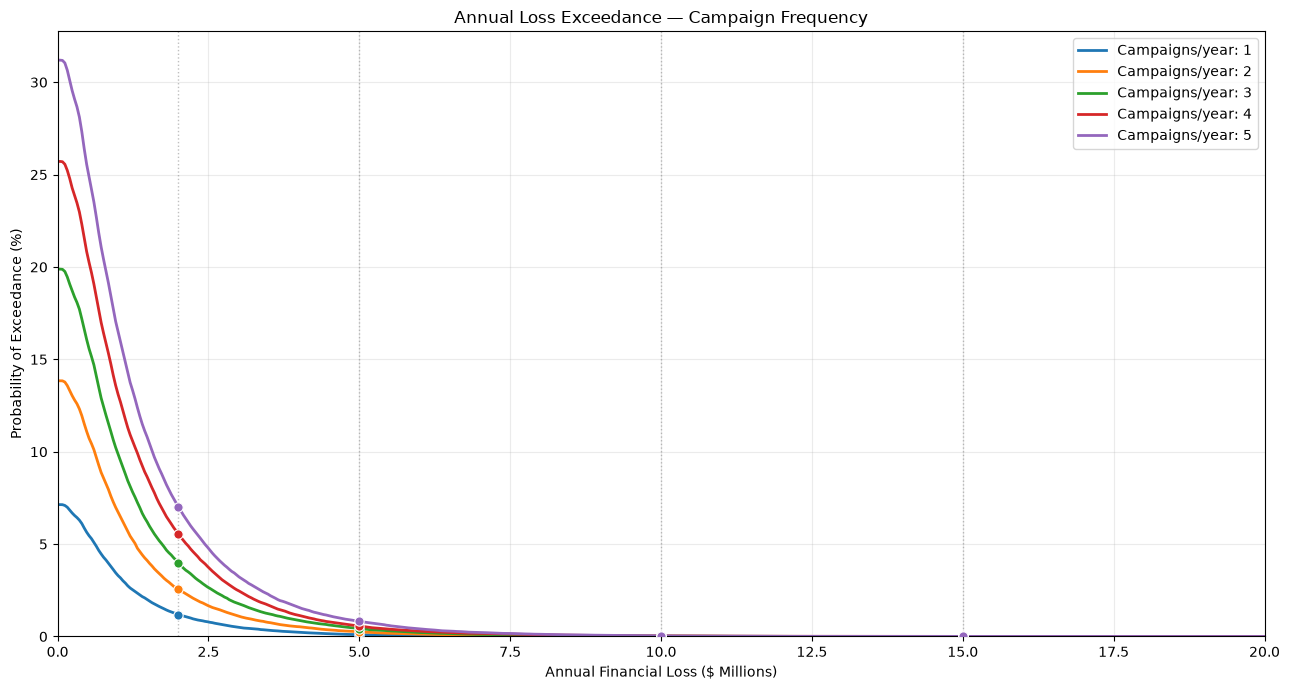


Exceedance Probability at Selected Loss Thresholds


,Scenario,P(Loss > $2M),P(Loss > $5M),P(Loss > $10M),P(Loss > $15M)
0,Campaigns/year: 1,1.19%,0.09%,0.00%,0.00%
1,Campaigns/year: 2,2.55%,0.25%,0.01%,0.00%
2,Campaigns/year: 3,3.99%,0.43%,0.02%,0.00%
3,Campaigns/year: 4,5.55%,0.57%,0.03%,0.01%
4,Campaigns/year: 5,7.02%,0.81%,0.04%,0.00%


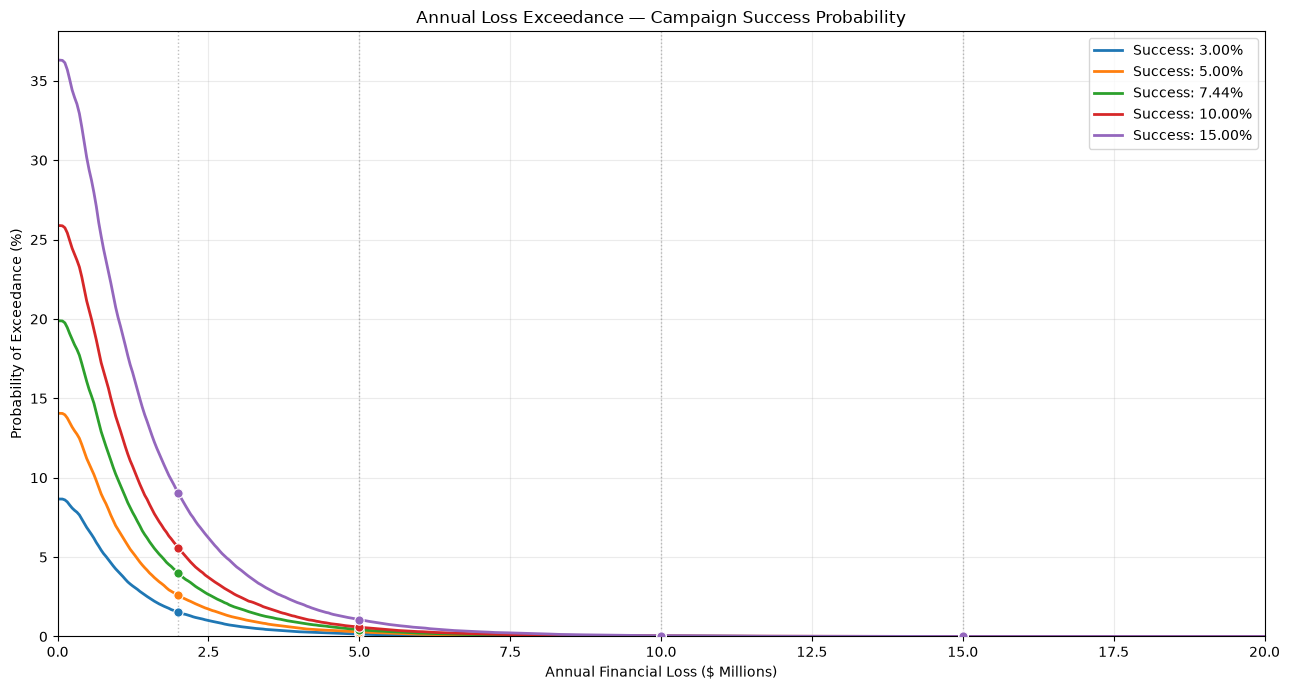


Exceedance Probability at Selected Loss Thresholds


,Scenario,P(Loss > $2M),P(Loss > $5M),P(Loss > $10M),P(Loss > $15M)
0,Success: 3.00%,1.52%,0.15%,0.01%,0.00%
1,Success: 5.00%,2.59%,0.29%,0.02%,0.00%
2,Success: 7.44%,3.99%,0.43%,0.02%,0.00%
3,Success: 10.00%,5.58%,0.59%,0.03%,0.01%
4,Success: 15.00%,9.03%,1.06%,0.05%,0.00%


In [12]:
# Cell 5 — Full Annual Loss Exceedance Curves with Markers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

IMPORTANT_THRESHOLDS = [2, 5, 10, 15]  # $ Millions


def plot_exceedance_curves(
    annual_losses_by_scenario,
    parameter,
    max_loss_millions=20,
    important_thresholds=IMPORTANT_THRESHOLDS,
):
    thresholds = np.linspace(
        0,
        max_loss_millions * 1_000_000,
        500,
    )

    scenarios = sorted(
        [
            (key, losses)
            for key, losses in annual_losses_by_scenario.items()
            if key[0] == parameter
        ],
        key=lambda item: item[0][1],
    )

    fig, ax = plt.subplots(figsize=(13, 7))
    comparison_rows = []

    # Vertical reference lines at important loss thresholds
    for threshold_m in important_thresholds:
        if threshold_m <= max_loss_millions:
            ax.axvline(
                threshold_m,
                color="gray",
                linestyle=":",
                linewidth=1,
                alpha=0.5,
            )

    # Plot each scenario
    for (name, value), losses in scenarios:

        sorted_losses = np.sort(losses)

        # Full exceedance curve
        probabilities = 1 - (
            np.searchsorted(
                sorted_losses,
                thresholds,
                side="right",
            ) / len(sorted_losses)
        )

        if parameter == "success_probability":
            label = f"Success: {value:.2%}"
        else:
            label = f"Campaigns/year: {value:g}"

        line, = ax.plot(
            thresholds / 1_000_000,
            probabilities * 100,
            linewidth=2,
            label=label,
        )

        # Mark and calculate important points
        row = {"Scenario": label}

        for threshold_m in important_thresholds:
            threshold_usd = threshold_m * 1_000_000

            probability = np.mean(
                losses > threshold_usd
            )

            row[f"P(Loss > ${threshold_m:g}M)"] = probability

            if threshold_m <= max_loss_millions:
                ax.scatter(
                    threshold_m,
                    probability * 100,
                    color=line.get_color(),
                    s=45,
                    edgecolor="white",
                    linewidth=0.8,
                    zorder=5,
                )

        comparison_rows.append(row)

    ax.set_xlabel("Annual Financial Loss ($ Millions)")
    ax.set_ylabel("Probability of Exceedance (%)")

    ax.set_title(
        "Annual Loss Exceedance — "
        + (
            "Campaign Success Probability"
            if parameter == "success_probability"
            else "Campaign Frequency"
        )
    )

    ax.set_xlim(0, max_loss_millions)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")

    plt.tight_layout()
    plt.show()

    # Comparison table with exact probabilities
    comparison_df = pd.DataFrame(comparison_rows)

    print("\nExceedance Probability at Selected Loss Thresholds")

    display(
        comparison_df.style.format({
            column: "{:.2%}"
            for column in comparison_df.columns
            if column != "Scenario"
        })
    )

    return comparison_df


# Chart 1 — Varying attack campaign frequency
campaign_exceedance = plot_exceedance_curves(
    annual_losses_by_scenario,
    parameter="campaign_rate",
)

# Chart 2 — Varying campaign success probability
success_exceedance = plot_exceedance_curves(
    annual_losses_by_scenario,
    parameter="success_probability",
)

In [11]:
# Combined sensitivity summary
# Changes relative to baseline

baseline = results[
    (results["parameter"] == "campaign_rate")
    & (results["parameter_value"] == 3)
].iloc[0]

comparison = results.copy()

comparison["aal_change_pct"] = (
    comparison["aal_usd"] / baseline["aal_usd"] - 1
) * 100

comparison["exceedance_2m_change_pp"] = (
    comparison["p_loss_gt_2m"]
    - baseline["p_loss_gt_2m"]
) * 100

comparison["scenario"] = comparison.apply(
    lambda row: (
        f"{row['parameter_value']:g} campaigns/year"
        if row["parameter"] == "campaign_rate"
        else f"{row['parameter_value']:.2%} success"
    ),
    axis=1,
)

display(
    comparison[
        [
            "scenario",
            "aal_usd",
            "aal_change_pct",
            "p_loss_gt_2m",
            "exceedance_2m_change_pp",
        ]
    ].rename(columns={
        "scenario": "Scenario",
        "aal_usd": "AAL",
        "aal_change_pct": "AAL Change (%)",
        "p_loss_gt_2m": "P(Loss > $2M)",
        "exceedance_2m_change_pp":
            "Change in Exceedance (pp)",
    }).style.format({
        "AAL": "${:,.0f}",
        "AAL Change (%)": "{:+.1f}%",
        "P(Loss > $2M)": "{:.2%}",
        "Change in Exceedance (pp)": "{:+.2f} pp",
    })
)

,Scenario,AAL,AAL Change (%),P(Loss > $2M),Change in Exceedance (pp)
0,1 campaigns/year,"$89,747",-67.1%,1.19%,-2.81 pp
1,2 campaigns/year,"$183,109",-32.9%,2.55%,-1.44 pp
2,3 campaigns/year,"$272,725",+0.0%,3.99%,+0.00 pp
3,4 campaigns/year,"$363,766",+33.4%,5.55%,+1.55 pp
4,5 campaigns/year,"$455,651",+67.1%,7.02%,+3.03 pp
5,3.00% success,"$112,089",-58.9%,1.52%,-2.47 pp
6,5.00% success,"$186,827",-31.5%,2.59%,-1.40 pp
7,7.44% success,"$272,725",+0.0%,3.99%,+0.00 pp
8,10.00% success,"$368,591",+35.2%,5.58%,+1.59 pp
9,15.00% success,"$558,446",+104.8%,9.03%,+5.04 pp


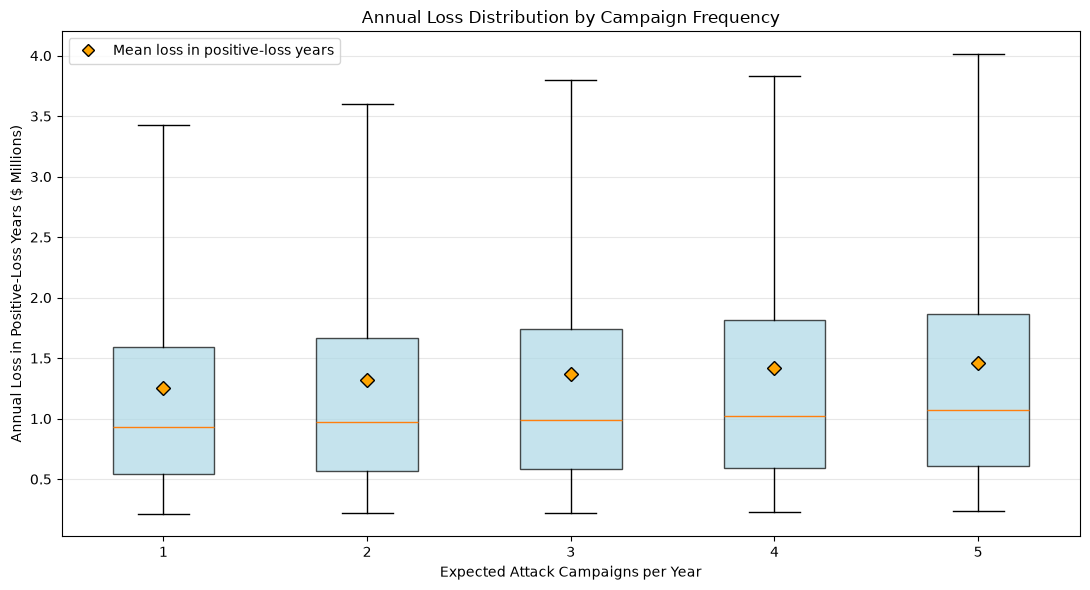


Unconditional AAL (includes zero-loss years):
1: $89,747
2: $183,109
3: $272,725
4: $363,766
5: $455,651


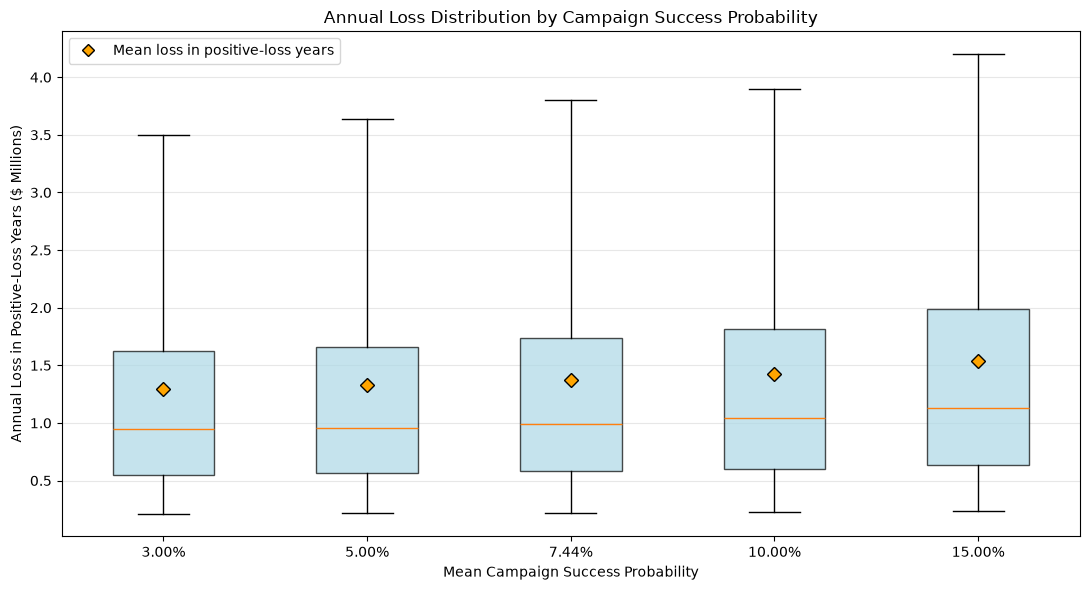


Unconditional AAL (includes zero-loss years):
3.00%: $112,089
5.00%: $186,827
7.44%: $272,725
10.00%: $368,591
15.00%: $558,446


In [ ]:
# Box-and-Whisker Plots for Annual Loss Sensitivity

import numpy as np
import matplotlib.pyplot as plt


def plot_annual_loss_boxplots(
    annual_losses_by_scenario,
    parameter,
):
    scenarios = sorted(
        [
            (key, losses)
            for key, losses in annual_losses_by_scenario.items()
            if key[0] == parameter
        ],
        key=lambda item: item[0][1],
    )

    data = []
    labels = []
    unconditional_aals = []

    for (name, value), losses in scenarios:

        # Keep only years with positive annual losses
        positive_losses = losses[losses > 0]

        data.append(positive_losses / 1_000_000)

        # AAL includes ALL simulated years
        unconditional_aals.append(losses.mean() / 1_000_000)

        if parameter == "success_probability":
            labels.append(f"{value:.2%}")
        else:
            labels.append(f"{value:g}")

    fig, ax = plt.subplots(figsize=(11, 6))

    box = ax.boxplot(
        data,
        tick_labels=labels,
        showmeans=True,
        meanprops=dict(
            marker="D",
            markerfacecolor="orange",
            markeredgecolor="black",
            markersize=7,
        ),
        showfliers=False,
        patch_artist=True,
        whis=(5, 95),
    )

    for patch in box["boxes"]:
        patch.set_facecolor("lightblue")
        patch.set_alpha(0.7)

    if parameter == "success_probability":
        xlabel = "Mean Campaign Success Probability"
        title = "Annual Loss Distribution by Campaign Success Probability"
    else:
        xlabel = "Expected Attack Campaigns per Year"
        title = "Annual Loss Distribution by Campaign Frequency"

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Annual Loss in Positive-Loss Years ($ Millions)")
    ax.set_title(title)

    ax.grid(axis="y", alpha=0.3)

    # Legend
    ax.plot(
        [],
        [],
        marker="D",
        linestyle="None",
        color="orange",
        markeredgecolor="black",
        label="Mean loss in positive-loss years",
    )

    ax.legend(loc="upper left")

    plt.tight_layout()
    plt.show()

    # Show unconditional AAL separately
    print("\nUnconditional AAL (includes zero-loss years):")

    for label, aal in zip(labels, unconditional_aals):
        print(f"{label}: ${aal * 1_000_000:,.0f}")


# Plot 1 — Campaign frequency
plot_annual_loss_boxplots(
    annual_losses_by_scenario,
    parameter="campaign_rate",
)

# Plot 2 — Campaign success probability
plot_annual_loss_boxplots(
    annual_losses_by_scenario,
    parameter="success_probability",
)

In [ ]:
#Step 6B: Loss Magnitude Sensitivity Analysis
#Confirm the exact configuration structure and the current incident simulation interface.

from pprint import pprint
import inspect

from config.model_config import get_config
from src.incident_simulation import simulate_incidents
from src.calibration import reputation_probabilities

cfg = get_config()

print("=== REPUTATION CONFIG ===")
pprint(cfg["reputation"])

print("\n=== INCIDENT SIMULATION SIGNATURE ===")
print(inspect.signature(simulate_incidents))

print("\n=== REPUTATION PROBABILITY SIGNATURE ===")
print(inspect.signature(reputation_probabilities))

print("\n=== CALIBRATION CONFIG KEYS ===")
print(list(cfg.keys()))

=== REPUTATION CONFIG ===
{'affected_count_rounding': 'round_to_nearest_integer_and_clip_0_to_customer_total',
 'affected_customers': {'family': 'pert',
                        'max': 3000,
                        'min': 300,
                        'mode': 1500,
                        'shape_lambda': 4.0},
 'churn': {'affected': {'distribution': 'binomial',
                        'probability_model': 'affected_churn',
                        'trials': 'affected_customers'},
           'unaffected': {'distribution': 'binomial',
                          'probability_model': 'unaffected_churn',
                          'trials': 'unaffected_customers'}},
 'loss_per_churned_customer_usd': 210000,
 'loss_per_lost_deal_usd': 210000,
 'lost_deals': {'distribution': 'binomial',
                'probability_model': 'lost_deal',
                'trials': 'otherwise_won_opportunities'},
 'note': 'No additional multi-year customer lifetime value or double counting '
         'of lost deals an

In [15]:
from pprint import pprint
from config.model_config import get_config

cfg = get_config()

print("=== PROBABILITIES CONFIG ===")
pprint(cfg["probabilities"], sort_dicts=False)

print("\n=== CALIBRATION CONFIG ===")
pprint(cfg["calibration"], sort_dicts=False)

print("\n=== DEPENDENCE CONFIG ===")
pprint(cfg["dependence"], sort_dicts=False)

=== PROBABILITIES CONFIG ===
{'public_visibility': {'family': 'calibrated_logistic',
                       'target': 0.3,
                       'target_type': 'unconditional',
                       'severity_or': 2.0,
                       'visibility_or': 1.0,
                       'regulator_or': 1.0,
                       'intercept': None},
 'notification': {'family': 'calibrated_logistic',
                  'target': 0.75,
                  'target_type': 'unconditional',
                  'severity_or': 2.0,
                  'visibility_or': 1.0,
                  'regulator_or': 1.0,
                  'intercept': None},
 'regulatory_engagement': {'family': 'calibrated_logistic',
                           'target': 0.1,
                           'target_type': 'unconditional',
                           'severity_or': 2.0,
                           'visibility_or': 1.0,
                           'regulator_or': 1.0,
                           'intercept': None},
 'ext

Sensitivity analysis for loss magnitude continued in a separate notebook